# Supplementary Figure 1 — Full vs LOCO TMB axis correlation

Output: `results/figures/supplementary/supp_fig1/full_vs_loco.pdf`

Source: `local/exploratory/21_loco_analysis.ipynb`

PDF export uses TrueType fonts so text remains editable in Adobe Illustrator/InDesign.

In [1]:
import socket
import os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser(
        "~/Documents/research/scg/protein-master/v2_pancan_batch_corrected"
    )

LOCO_DIR = f"{BASE_DIR}/analysis/02_loco/positive"
AXIS_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores/tcga_xena"
OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig1"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"BASE_DIR: {BASE_DIR}")

BASE_DIR: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected


In [2]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from scipy.stats import pearsonr

# Editable text in Adobe Illustrator / InDesign
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

In [3]:
def corr_with_p(row, x="TMB_axis_score", y="log_mut"):
    r, p = pearsonr(row[x], row[y])
    return pd.Series({"r": r, "p": p})


summary = pd.read_csv(f"{LOCO_DIR}/corr_tmb_axis_score_vs_tmb.csv")
corr_df = summary[["cancer_type", "pearson_r_tmb_vs_tmb_axis", "pval_tmb_vs_tmb_axis"]].copy()
corr_df = corr_df.rename(
    columns={
        "pearson_r_tmb_vs_tmb_axis": "r",
        "pval_tmb_vs_tmb_axis": "p",
    }
)

full_data = pd.read_parquet(f"{AXIS_DIR}/axis_sample_level.parquet")
corr_df_full = (
    full_data.groupby("cancer_type", group_keys=False)
    .apply(lambda x: corr_with_p(x, "TMB_axis_score"), include_groups=False)
    .reset_index()
)

corr_df = corr_df[["cancer_type", "r", "p"]].merge(
    corr_df_full, on="cancer_type", suffixes=("_loco", "_full")
)
corr_df.head()

,cancer_type,r_loco,p_loco,r_full,p_full
0,KICH,0.535203,3.658020e-06,0.541046,2.728597e-06
1,STAD,0.518533,9.904364e-30,0.541203,1.006760e-32
2,LUAD,0.496963,3.146846e-33,0.516444,3.507853e-36
3,ACC,0.481556,7.025079e-06,0.495984,3.350494e-06
4,UCS,0.473250,2.009517e-04,0.480967,1.524258e-04


Saved: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/supplementary/supp_fig1/full_vs_loco.pdf


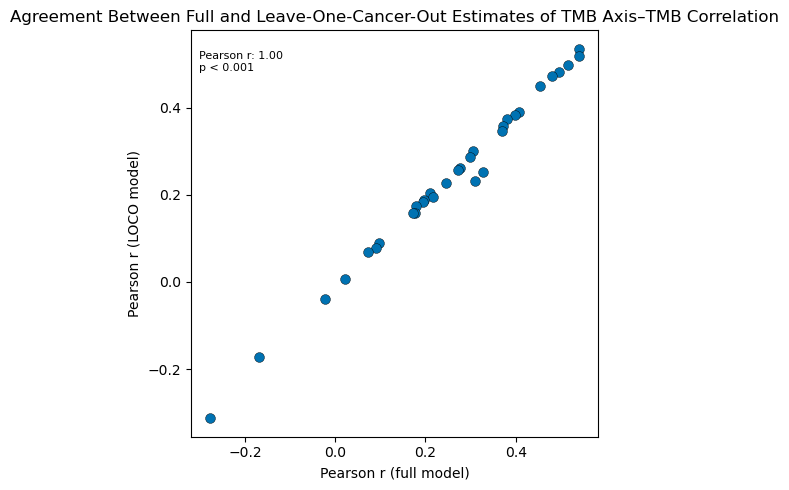

In [ ]:
r, p = pearsonr(corr_df["r_full"], corr_df["r_loco"])

if p < 0.001:
    p_text = "p < 0.001"
else:
    p_text = f"p = {p:.3f}"

fig, ax = plt.subplots(figsize=(5, 5))

sns.scatterplot(
    data=corr_df,
    x="r_full",
    y="r_loco",
    color=COLORS["low"],
    edgecolor=COLORS["black"],
    linewidth=0.3,
    s=50,
    ax=ax,
)

text = f"Pearson r: {r:.3f}\n{p_text}"
ax.annotate(
    text,
    xy=(0.02, 0.9),
    xycoords="axes fraction",
    fontsize=8,
)

ax.set_xlabel("Pearson r (full model)")
ax.set_ylabel("Pearson r (LOCO model)")
ax.set_title(
    "Agreement Between Full and Leave-One-Cancer-Out Estimates of TMB Axis–TMB Correlation"
)
fig.tight_layout()

out_pdf = f"{OUT_DIR}/full_vs_loco.pdf"
fig.savefig(out_pdf, dpi=300, bbox_inches="tight")
print(f"Saved: {out_pdf}")

plt.show()